# Part 1: Data Preparation and Exploratory Analysis

**Personal project: Electric Vehicle Adoption in Washington State**

**Name:** Bernard Issifu

This notebook introduces the dataset, cleans it, builds the features used later, and explores how
electric vehicle (EV) adoption varies over time and across Washington. The same steps are implemented in
R in `r/01_data_preparation_eda.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

---
# 1. The dataset

The **Electric Vehicle Population Data** (Washington State Department of Licensing, published on
data.wa.gov under the Open Database License, ODbL) lists every battery-electric (BEV) and plug-in hybrid
(PHEV) vehicle currently registered with the state. This snapshot was last updated on **14 October
2026** and has 300,142 vehicles. Each row gives the vehicle's county, city and ZIP code, model year,
make and model, EV type, electric range, eligibility for the state's clean-fuel incentive (CAFV), the
legislative district, the electric utility serving the address, and the 2020 census tract.

The file is stored compressed (`data/ev_population.csv.gz`) without three high-entropy columns that
are not needed (partial VIN, DOL vehicle ID and point coordinates).

In [2]:
# ZIP code, census tract and legislative district are labels, so they are read as text
raw = pd.read_csv("../data/ev_population.csv.gz",
                  dtype={"Postal Code": "string", "2020 GEOID": "string",
                         "Legislative District": "string"})
print(raw.shape)
raw.head()

(300142, 13)


,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 GEOID
0,King,Seattle,WA,98177,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,32,CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),53033000402
1,Thurston,Yelm,WA,98597,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,2,PUGET SOUND ENERGY INC,53067012412
2,King,Sammamish,WA,98075,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,41,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53033032224
3,Island,Oak Harbor,WA,98277,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,47.0,10,PUGET SOUND ENERGY INC,53029970800
4,Kitsap,Bremerton,WA,98312,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,21.0,26,PUGET SOUND ENERGY INC,53035080600


In [3]:
raw["Electric Vehicle Type"].value_counts().to_frame("vehicles").assign(
    percent=lambda t: (t["vehicles"] / t["vehicles"].sum() * 100).round(1))

,vehicles,percent
Electric Vehicle Type,,
Battery Electric Vehicle (BEV),241840,80.6
Plug-in Hybrid Electric Vehicle (PHEV),58302,19.4


---
# 2. Data quality

In [4]:
missing = raw.isna().sum()
print("Missing values per column (only columns with any):")
print(missing[missing > 0])
print()
print("Vehicles registered outside Washington:", int((raw["State"] != "WA").sum()))
print("Share of vehicles with electric range recorded as 0:",
      round((raw["Electric Range"] == 0).mean(), 3))

Missing values per column (only columns with any):
County                   15
City                     15
Postal Code              15
Electric Range           35
Legislative District    790
Electric Utility         15
2020 GEOID               15
dtype: int64

Vehicles registered outside Washington: 789
Share of vehicles with electric range recorded as 0: 0.657


In [5]:
# Electric range 0 means 'not yet researched' by the state, and it is concentrated in recent years
rng0 = raw.groupby("Model Year")["Electric Range"].apply(lambda s: (s == 0).mean())
rng0.loc[2015:].round(2).to_frame("share_range_0").T

Model Year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027
share_range_0,0.0,0.0,0.0,0.0,0.0,0.01,0.75,0.83,0.88,0.78,0.8,0.88,0.95


**Interpretation.** The data are almost complete: 15 records lack a county, ZIP code or utility, 790
lack a legislative district (all but one registered outside Washington, which has no district for
them), and 35 lack an electric range.
The main quality issue is hidden: electric range is recorded as **0 for 66% of vehicles**, because the
state stopped researching ranges for new models; the share is near 0 up to model year 2020 and
75–95% from 2021. Range is therefore unusable as a feature for recent vehicles.

---
# 3. Cleaning and feature engineering

In [6]:
df = raw.copy()
steps = [("Raw data", len(df))]

# (1) Keep vehicles registered in Washington (out-of-state rows are owners stationed elsewhere)
df = df[df["State"] == "WA"]
steps.append(("Keep Washington registrations", len(df)))

# (2) Drop the few rows missing location fields
df = df.dropna(subset=["County", "Postal Code", "Electric Utility", "Legislative District"])
steps.append(("Drop rows missing location fields", len(df)))

# (3) Keep model year 2011 onward: the modern mass-market EV era (Nissan Leaf, Chevrolet Volt)
df = df[df["Model Year"] >= 2011]
steps.append(("Keep model year 2011 onward", len(df)))

pd.DataFrame(steps, columns=["step", "rows"])

,step,rows
0,Raw data,300142
1,Keep Washington registrations,299353
2,Drop rows missing location fields,299352
3,Keep model year 2011 onward,299303


In [7]:
# (a) Outcome for Question 1: 1 = battery-electric (BEV), 0 = plug-in hybrid (PHEV)
df["bev"] = df["Electric Vehicle Type"].str.startswith("Battery").astype(int)

# (b) Region: Seattle metro (King, Snohomish, Pierce), other western WA, or eastern WA
eastern = ["Adams", "Asotin", "Benton", "Chelan", "Columbia", "Douglas", "Ferry", "Franklin",
           "Garfield", "Grant", "Kittitas", "Klickitat", "Lincoln", "Okanogan", "Pend Oreille",
           "Spokane", "Stevens", "Walla Walla", "Whitman", "Yakima"]
df["region"] = np.select([df["County"].isin(["King", "Snohomish", "Pierce"]),
                          df["County"].isin(eastern)],
                         ["Seattle metro", "Eastern WA"], "Other western WA")

# (c) Urbanity proxy: number of EVs registered in the same city (log scale later)
df["city_evs"] = df.groupby("City")["City"].transform("size")

# (d) Primary electric utility: the first one listed (some addresses list several)
df["utility"] = df["Electric Utility"].str.split("|").str[0]
top_util = df["utility"].value_counts().head(6).index
df["utility"] = df["utility"].where(df["utility"].isin(top_util), "Other")

# (e) County: keep the 15 largest, group the rest
top_cty = df["County"].value_counts().head(15).index
df["county_grp"] = df["County"].where(df["County"].isin(top_cty), "Other")

# (f) Make: Tesla flag, used for the ZIP profiles in Question 2
df["tesla"] = (df["Make"] == "TESLA").astype(int)

df = df.rename(columns={"Postal Code": "zip", "Model Year": "model_year",
                        "Legislative District": "leg_district"})
print(df.shape)
print(f"BEV share after cleaning: {df['bev'].mean():.2%}")
df["utility"].value_counts()

(299303, 19)
BEV share after cleaning: 80.58%


utility
PUGET SOUND ENERGY INC             174776
BONNEVILLE POWER ADMINISTRATION     63900
CITY OF SEATTLE - (WA)              48872
Other                                4855
PACIFICORP                           2782
PUD NO 1 OF CHELAN COUNTY            2060
MODERN ELECTRIC WATER COMPANY        2058
Name: count, dtype: int64

---
# 4. Exploratory analysis

## 4.1 Growth over time and the BEV/PHEV mix

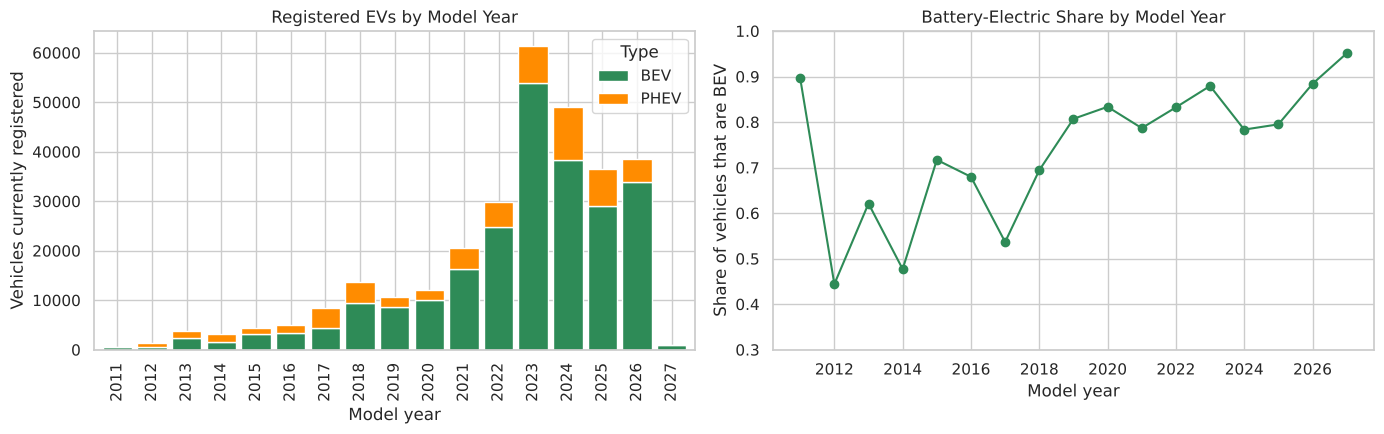

model_year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027
vehicles,520.000,1261.000,3765.000,3090.000,4329.000,4980.00,8332.000,13705.000,10638.000,11981.000,20604.000,29844.000,61316.000,48978.000,36484.000,38436.000,1040.000
bev_share,0.896,0.444,0.621,0.477,0.717,0.68,0.537,0.694,0.807,0.833,0.787,0.832,0.879,0.783,0.795,0.884,0.951


In [8]:
by_year = df.groupby("model_year").agg(vehicles=("bev", "size"), bev_share=("bev", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

counts = df.groupby(["model_year", "Electric Vehicle Type"]).size().unstack(fill_value=0)
counts.columns = ["BEV", "PHEV"]
counts.plot(kind="bar", stacked=True, ax=axes[0], color=["seagreen", "darkorange"], width=0.85)
axes[0].set_title("Registered EVs by Model Year")
axes[0].set_xlabel("Model year")
axes[0].set_ylabel("Vehicles currently registered")
axes[0].legend(title="Type")

axes[1].plot(by_year.index, by_year["bev_share"], marker="o", color="seagreen")
axes[1].set_title("Battery-Electric Share by Model Year")
axes[1].set_xlabel("Model year")
axes[1].set_ylabel("Share of vehicles that are BEV")
axes[1].set_ylim(0.3, 1)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_model_year.png", dpi=150)
plt.show()

by_year.round(3).T

**Interpretation.** Registrations rise steeply with model year: about 1,000–5,000 vehicles per year up
to 2016, then 20,604 for 2021, 29,844 for 2022 and a peak of 61,316 for 2023 (newer model years are
partly still being sold; 2027 is just starting). Older registrations are partly survivors, so counts by
model year understate early sales. The BEV share is lower and erratic for model years 2012–2018 (44–72%; the 520
surviving 2011 vehicles are 90% BEV, mostly Nissan Leafs), then sits around 78–88%; it dips in 2024–2025 (78–80%) as more plug-in hybrids arrived, before rising again.

## 4.2 Top makes and regions

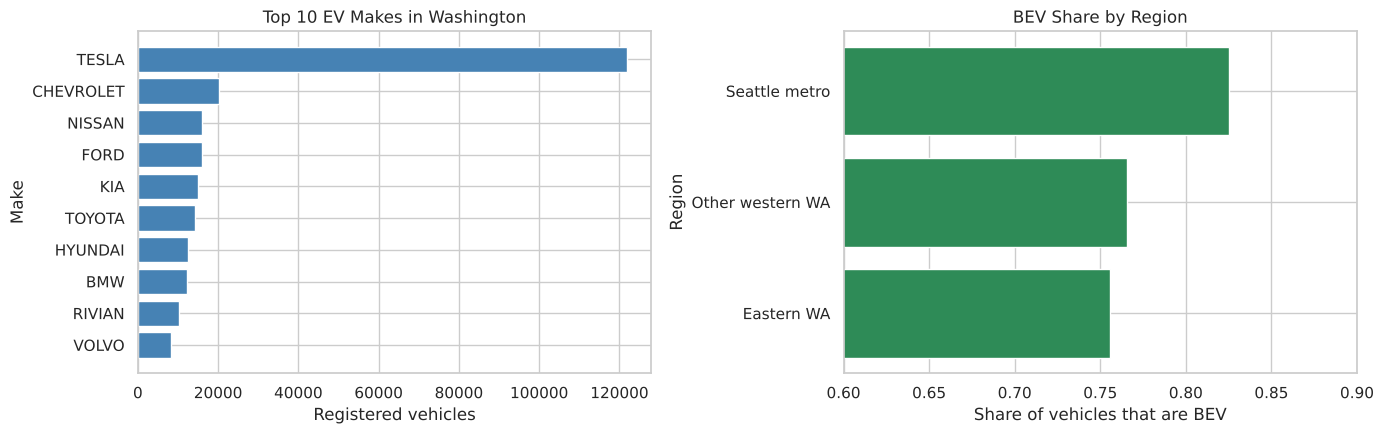

Tesla share of all EVs: 40.7%


,vehicles,bev_share
region,,
Eastern WA,25869,0.755
Other western WA,66519,0.766
Seattle metro,206915,0.825


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
top_makes = df["Make"].value_counts().head(10)
axes[0].barh(top_makes.index[::-1], top_makes.values[::-1], color="steelblue")
axes[0].set_title("Top 10 EV Makes in Washington")
axes[0].set_xlabel("Registered vehicles")
axes[0].set_ylabel("Make")

reg = df.groupby("region")["bev"].agg(vehicles="size", bev_share="mean").sort_values("bev_share")
axes[1].barh(reg.index, reg["bev_share"], color="seagreen")
axes[1].set_title("BEV Share by Region")
axes[1].set_xlabel("Share of vehicles that are BEV")
axes[1].set_ylabel("Region")
axes[1].set_xlim(0.6, 0.9)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_makes_region.png", dpi=150)
plt.show()

print(f"Tesla share of all EVs: {df['tesla'].mean():.1%}")
reg.round(3)

In [10]:
cty = (df.groupby("County")["bev"].agg(vehicles="size", bev_share="mean")
       .sort_values("vehicles", ascending=False).head(15))
cty.round(3)

,vehicles,bev_share
County,,
King,143947,0.827
Snohomish,37802,0.844
Pierce,25166,0.787
Clark,18897,0.772
Thurston,11041,0.772
Kitsap,10381,0.774
Spokane,8775,0.737
Whatcom,7570,0.769
Benton,4546,0.764


**Interpretation.** Tesla dominates with about 41% of all registered EVs, far ahead of Chevrolet,
Ford, Nissan and Kia. Adoption is concentrated: King County alone holds about 48% of the state's EVs,
and the Seattle metro (King, Snohomish, Pierce) about 69%. The BEV share is highest in the Seattle metro
(82.5%) and lower in other western counties and in eastern Washington (about 76–77%), where longer
distances and fewer chargers may favour plug-in hybrids.

In [11]:
# Save the cleaned data for Parts 2 and 3
os.makedirs("../data/processed", exist_ok=True)
cols = ["County", "City", "zip", "model_year", "Make", "Model", "Electric Vehicle Type",
        "Electric Range", "leg_district", "bev", "region", "city_evs", "utility", "county_grp",
        "tesla"]
df[cols].to_csv("../data/processed/ev_clean_python.csv", index=False)
print("Saved", df[cols].shape)

Saved (299303, 15)


---
# 5. Summary and the two project questions

After cleaning, the data hold every EV of model year 2011 onward registered in Washington. About four
in five are fully battery-electric, adoption is concentrated in the Seattle metro, and Tesla accounts for
about two in five vehicles.

1. **Can location and time predict whether a registered EV is fully battery-electric rather than a
   plug-in hybrid?** Classification (logistic regression, decision tree, random forest) using model
   year, region, county, urbanity, utility and legislative district, but not make, model or range.
2. **What distinct EV-adoption profiles exist across Washington ZIP codes?** k-means clustering of
   ZIP-level fleet profiles (size, BEV share, Tesla share, share of recent models, brand diversity).